This notebook presents a close alternetive to Corcoran & Jones (2022). However, we also include the nodes in the filtration. The persistent densities have the following alternative definitions

1. H0 : Step in which the nodes are incorporated into the network
2. H1 : Step in which cycles are created

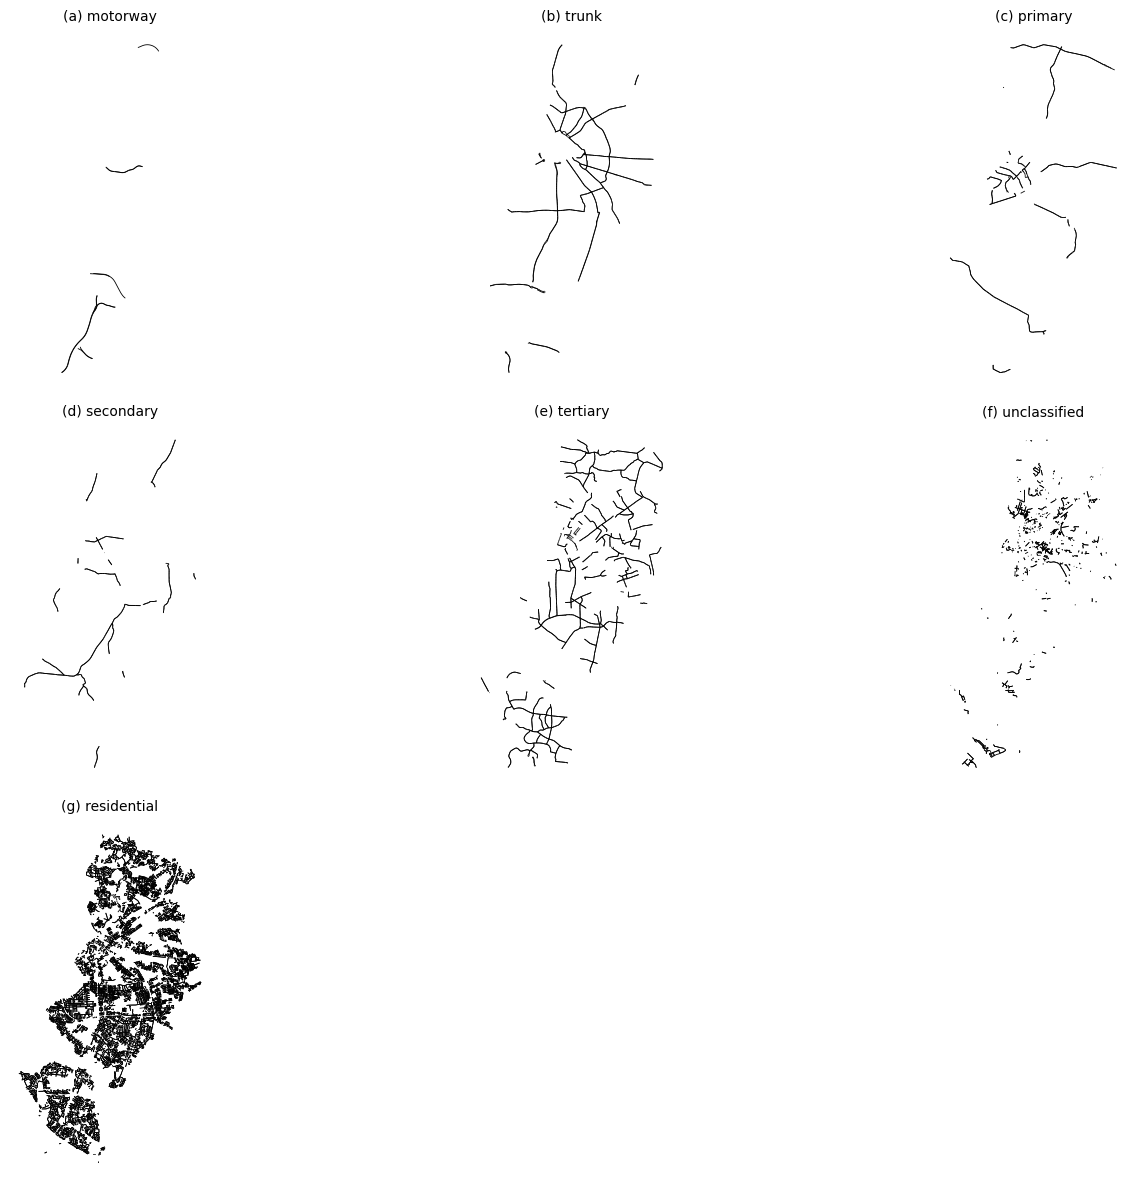

In [ ]:
# pip install osmnx matplotlib

import osmnx as ox
import matplotlib.pyplot as plt
import geopandas as gpd

# -----------------------------
# 1. SETTINGS
# -----------------------------
place = "Manchester, England, United Kingdom"

highway_order = [
    "motorway",
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "unclassified",
    "residential",
]

ox.settings.use_cache = True
ox.settings.log_console = True

# -----------------------------
# 2. DOWNLOAD FULL STREET GRAPH
# -----------------------------
G = ox.graph_from_place(place, network_type="drive", simplify=True)

# Convert to GeoDataFrame (edges only)
edges = ox.graph_to_gdfs(G, nodes=False)

# Some highways are stored as lists → normalize
edges["highway"] = edges["highway"].apply(
    lambda x: x[0] if isinstance(x, list) else x
)

# -----------------------------
# 3. PLOT EACH HIGHWAY TYPE
# -----------------------------
n = len(highway_order)
cols = 3
rows = int((n / cols) + 0.999)

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = axes.flatten()

for i, hw in enumerate(highway_order):
    ax = axes[i]

    subset = edges[edges["highway"] == hw]

    if not subset.empty:
        subset.plot(
            ax=ax,
            linewidth=0.6,
            color="black",
        )

    ax.set_title(f"({chr(97+i)}) {hw}", fontsize=10)
    ax.set_axis_off()

# Remove extra axes if any
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()



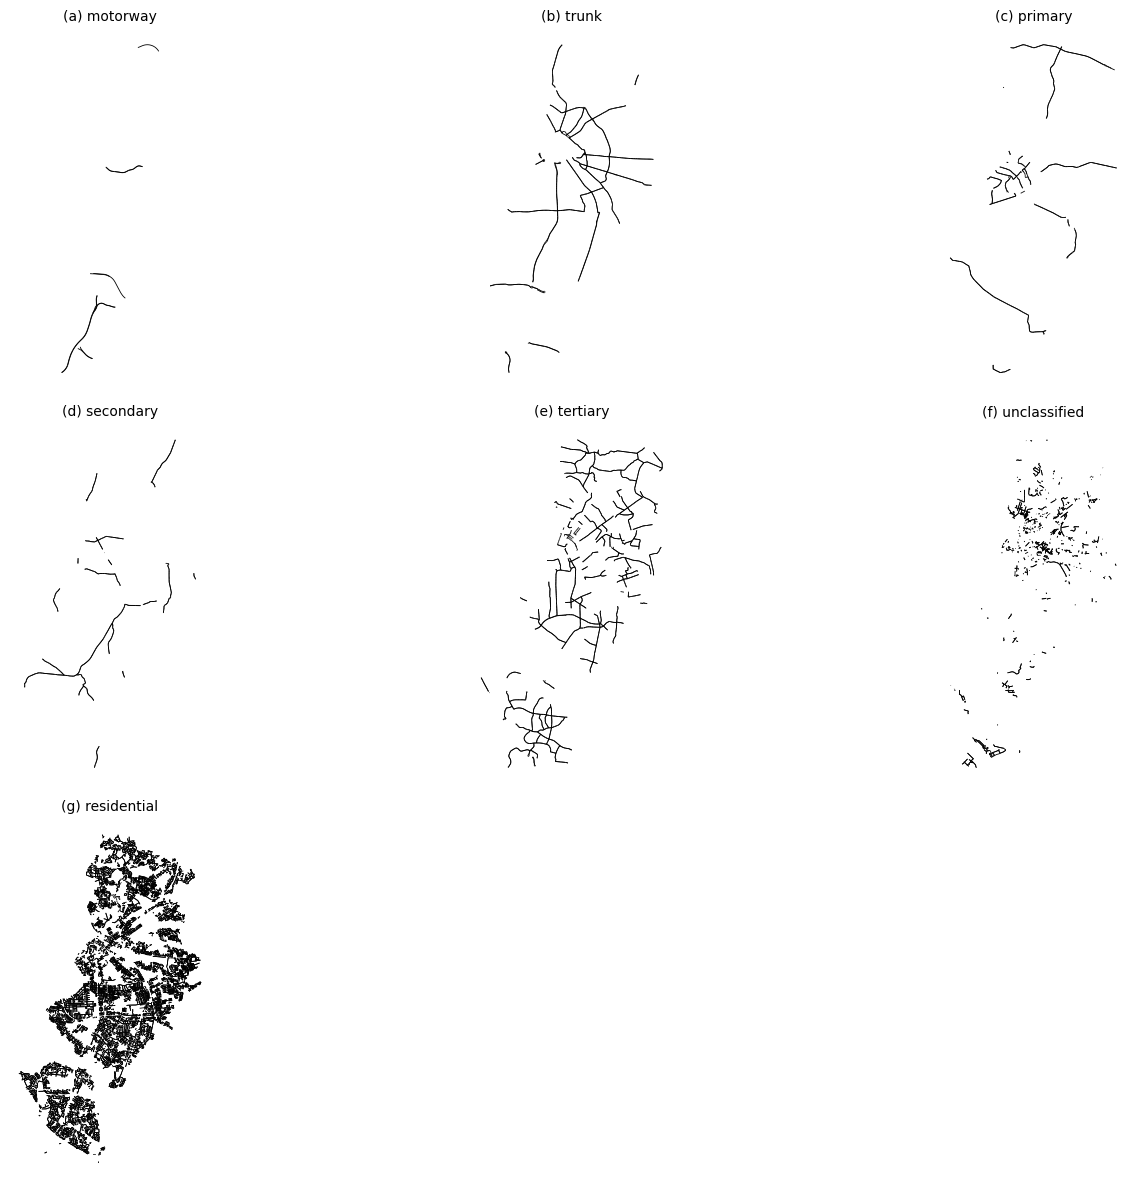

In [65]:
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

highway_order = [
    "motorway",
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "unclassified",
    "residential",
]

edges = ox.graph_to_gdfs(G, nodes=False)
edges["highway"] = edges["highway"].apply(
    lambda x: x[0] if isinstance(x, list) else x
)

n = len(highway_order)
cols = 3
rows = int((n / cols) + 0.999)

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = axes.flatten()

for i, hw in enumerate(highway_order):
    ax = axes[i]
    subset = edges[edges["highway"] == hw]
    if not subset.empty:
        subset.plot(ax=ax, linewidth=0.6, color="black")
    ax.set_title(f"({chr(97+i)}) {hw}", fontsize=10)
    ax.set_axis_off()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

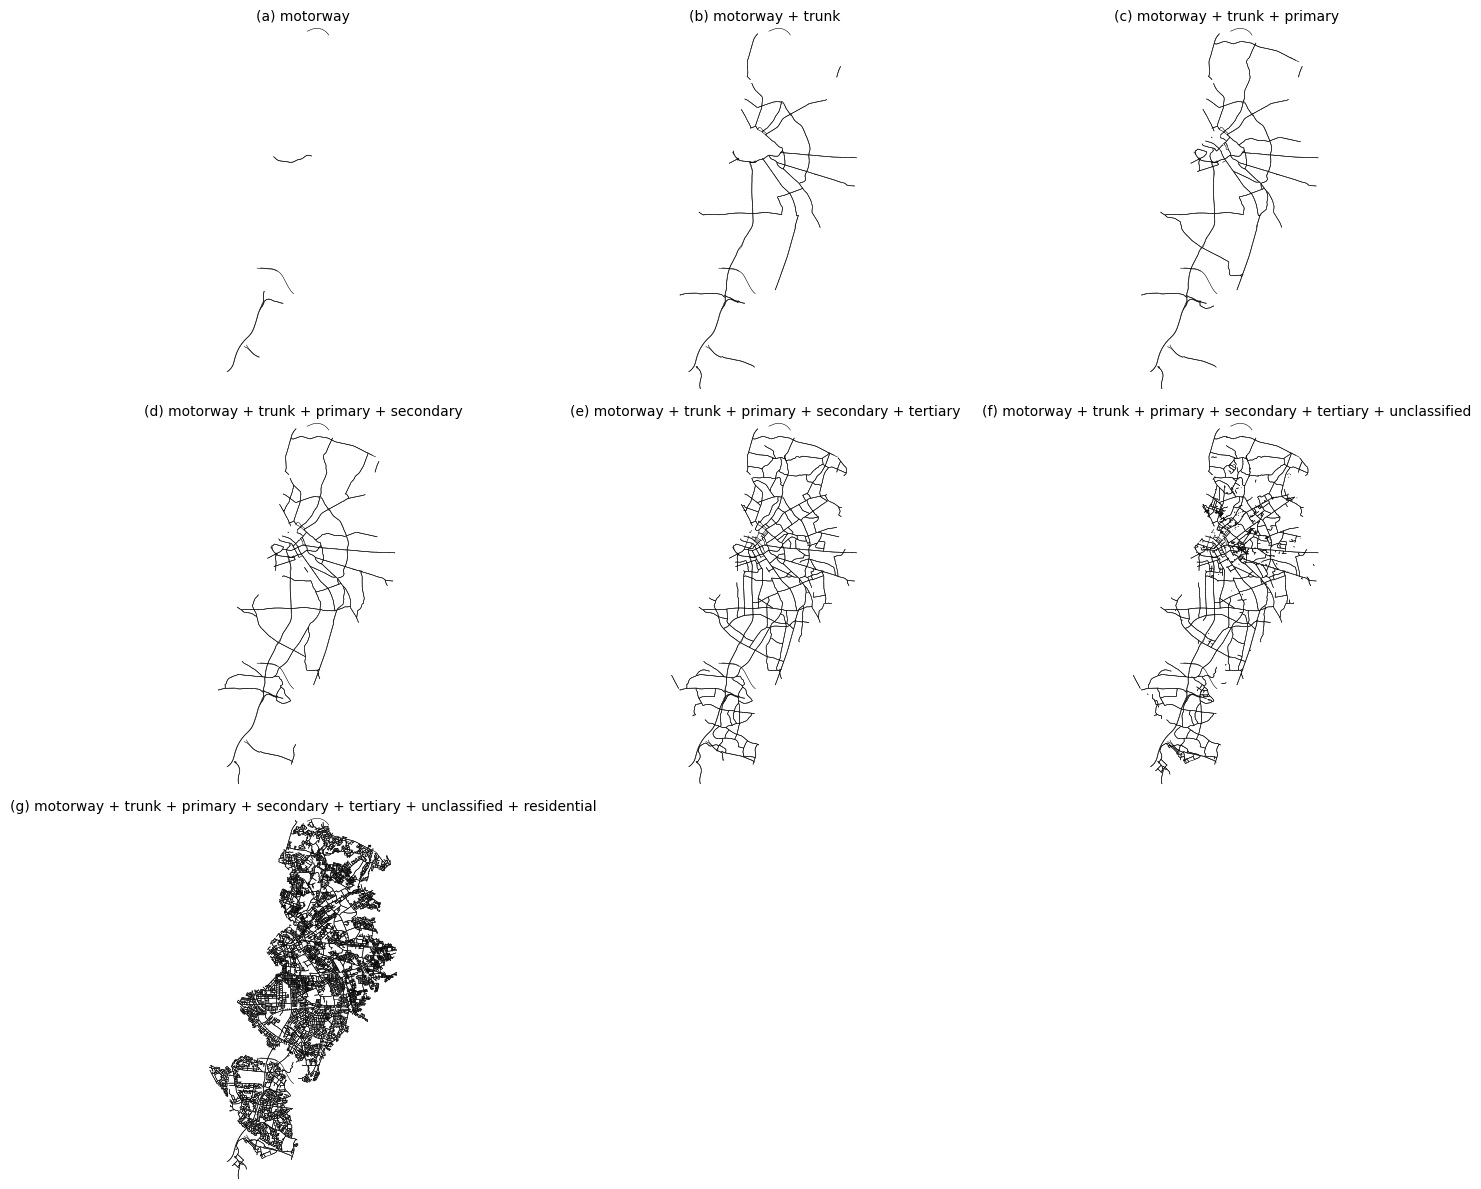

Final graph summary
Nodes: 14938
Edges: 18295

Simplex tree summary
Dimension: 1
Num vertices: 14938
Num simplices: 33233

Finite H1 intervals:
[]

Graph-theoretic diagnostics
Connected components: 47
Cycle rank: 3404

Betti numbers:
[47, 3404]


<Figure size 700x600 with 0 Axes>

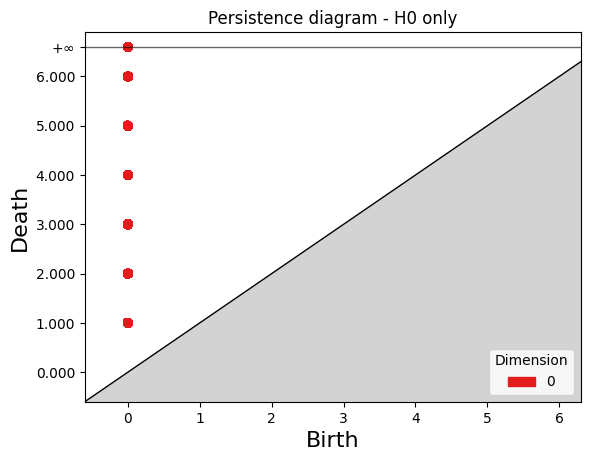

<Figure size 1000x400 with 0 Axes>

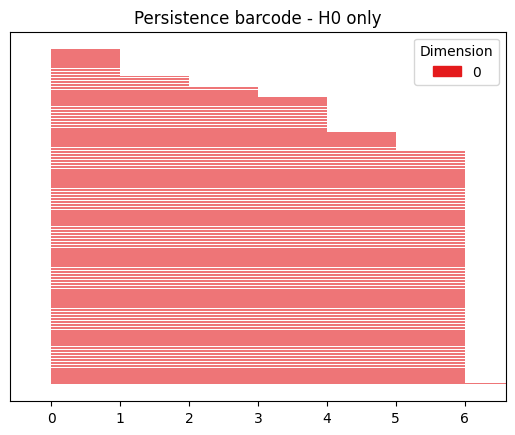

<Figure size 700x600 with 0 Axes>

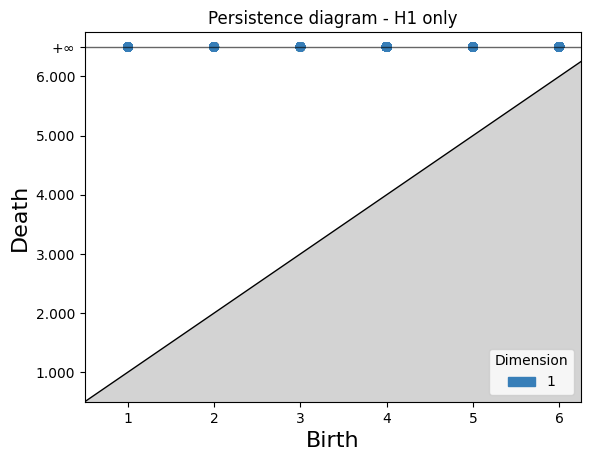

<Figure size 1000x400 with 0 Axes>

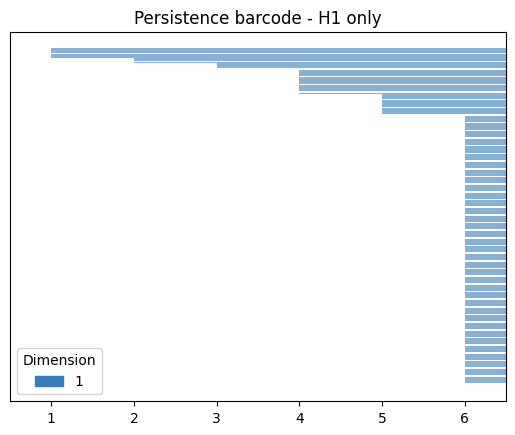


Step-by-step filtration summary

Step 0 -> all nodes + ['motorway']
Nodes: 14938
Edges: 39
Connected components: 14899
Cycle rank: 0

Step 1 -> all nodes + ['motorway', 'trunk']
Nodes: 14938
Edges: 1342
Connected components: 13690
Cycle rank: 94

Step 2 -> all nodes + ['motorway', 'trunk', 'primary']
Nodes: 14938
Edges: 1901
Connected components: 13188
Cycle rank: 151

Step 3 -> all nodes + ['motorway', 'trunk', 'primary', 'secondary']
Nodes: 14938
Edges: 2375
Connected components: 12766
Cycle rank: 203

Step 4 -> all nodes + ['motorway', 'trunk', 'primary', 'secondary', 'tertiary']
Nodes: 14938
Edges: 4189
Connected components: 11206
Cycle rank: 457

Step 5 -> all nodes + ['motorway', 'trunk', 'primary', 'secondary', 'tertiary', 'unclassified']
Nodes: 14938
Edges: 5210
Connected components: 10393
Cycle rank: 665

Step 6 -> all nodes + ['motorway', 'trunk', 'primary', 'secondary', 'tertiary', 'unclassified', 'residential']
Nodes: 14938
Edges: 18295
Connected components: 47
Cycle rank:

In [66]:
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import gudhi

# Step 0 = trunk, step 1 = primary, ...
filtration_time = {hw: i for i, hw in enumerate(highway_order)}

ox.settings.use_cache = True
ox.settings.log_console = True

edges = ox.graph_to_gdfs(G, nodes=False).copy()
edges["highway"] = edges["highway"].apply(
    lambda x: x[0] if isinstance(x, list) else x
)
edges = edges[edges["highway"].isin(highway_order)].copy()

xmin, ymin, xmax, ymax = edges.total_bounds

# -----------------------------
# PLOT FILTRATION SNAPSHOTS
# -----------------------------
n = len(highway_order)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = axes.flatten()

cumulative_types = []

for i, hw in enumerate(highway_order):
    cumulative_types.append(hw)
    ax = axes[i]
    subset = edges[edges["highway"].isin(cumulative_types)]
    if not subset.empty:
        subset.plot(ax=ax, linewidth=0.4, color="black")
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"({chr(97+i)}) " + " + ".join(cumulative_types), fontsize=10)
    ax.set_axis_off()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# -----------------------------
# BUILD SIMPLE UNDIRECTED GRAPH
# -----------------------------
H = nx.Graph()

for (u, v, k), row in edges.iterrows():
    hw = row["highway"]
    t = filtration_time[hw]
    if u == v:
        continue
    if H.has_edge(u, v):
        H[u][v]["filtration"] = min(H[u][v]["filtration"], t)
    else:
        H.add_edge(u, v, filtration=t)

# Collect ALL nodes from the original graph (not just those with edges in highway_order)
all_nodes = list(G.nodes())
for node in all_nodes:
    if node not in H:
        H.add_node(node)

print("Final graph summary")
print("Nodes:", H.number_of_nodes())
print("Edges:", H.number_of_edges())

# -----------------------------
# BUILD GUDHI SIMPLEX TREE
# Node filtration = 0 (all nodes present from step 0)
# Edge filtration = highway type step
# -----------------------------
st = gudhi.SimplexTree()

node_to_int = {node: i for i, node in enumerate(H.nodes())}

# All nodes inserted at filtration 0
for node in H.nodes():
    st.insert([node_to_int[node]], filtration=0.0)

# Edges inserted at their highway-type filtration step
for u, v, data in H.edges(data=True):
    st.insert([node_to_int[u], node_to_int[v]], filtration=float(data["filtration"]))

print("\nSimplex tree summary")
print("Dimension:", st.dimension())
print("Num vertices:", st.num_vertices())
print("Num simplices:", st.num_simplices())

# -----------------------------
# COMPUTE PERSISTENCE
# -----------------------------
diag = st.persistence(
    homology_coeff_field=2,
    persistence_dim_max=True
)

h0 = st.persistence_intervals_in_dimension(0)
h1 = st.persistence_intervals_in_dimension(1)

h1_finite = h1[np.isfinite(h1).all(axis=1)] if len(h1) > 0 else np.empty((0, 2))
print("\nFinite H1 intervals:")
print(h1_finite)

if len(h1_finite) > 0:
    h1_lengths = h1_finite[:, 1] - h1_finite[:, 0]
    print("\nFinite H1 bar lengths:")
    print(h1_lengths)

# -----------------------------
# GRAPH-THEORETIC CHECK
# -----------------------------
c = nx.number_connected_components(H)
m = H.number_of_edges()
n_nodes = H.number_of_nodes()
cycle_rank = m - n_nodes + c

print("\nGraph-theoretic diagnostics")
print("Connected components:", c)
print("Cycle rank:", cycle_rank)

bettis = st.betti_numbers()
print("\nBetti numbers:")
print(bettis)

# -----------------------------
# PLOT H0
# -----------------------------
if len(h0) > 0:
    h0_diag = [(0, (birth, death)) for birth, death in h0]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h0_diag)
    plt.title("Persistence diagram - H0 only")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h0_diag)
    plt.title("Persistence barcode - H0 only")
    plt.show()
else:
    print("\nNo H0 intervals found.")

# -----------------------------
# PLOT H1
# -----------------------------
if len(h1) > 0:
    h1_diag = [(1, (birth, death)) for birth, death in h1]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h1_diag)
    plt.title("Persistence diagram - H1 only")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h1_diag)
    plt.title("Persistence barcode - H1 only")
    plt.show()
else:
    print("\nNo H1 intervals found.")

# -----------------------------
# STEP-BY-STEP FILTRATION CHECK
# -----------------------------
# Step 0: all nodes + trunk edges
# Step 1: all nodes + trunk + primary edges
# ...
print("\nStep-by-step filtration summary")
for t in range(len(highway_order)):
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= t]
    G_t = nx.Graph()
    G_t.add_nodes_from(H.nodes())  # all nodes always present
    G_t.add_edges_from(edges_t)

    n_t = G_t.number_of_nodes()
    m_t = G_t.number_of_edges()
    c_t = nx.number_connected_components(G_t)
    cycle_rank_t = m_t - n_t + c_t

    print(f"\nStep {t} -> all nodes + {highway_order[:t+1]}")
    print("Nodes:", n_t)
    print("Edges:", m_t)
    print("Connected components:", c_t)
    print("Cycle rank:", cycle_rank_t)

In [70]:
import numpy as np

replacement = len(highway_order)

h0[np.isinf(h0)] = replacement
h1[np.isinf(h1)] = replacement

In [71]:
h0

array([[0., 1.],
       [0., 1.],
       [0., 1.],
       ...,
       [0., 7.],
       [0., 7.],
       [0., 7.]])

7
[1 2 3 4 5 6 7] [0.08114639 0.03369354 0.02832405 0.10470501 0.05456742 0.69440902
 0.00315457]
6
[1 2 3 4 5 6] [0.02761457 0.01674501 0.01527615 0.0746181  0.06110458 0.8046416 ]


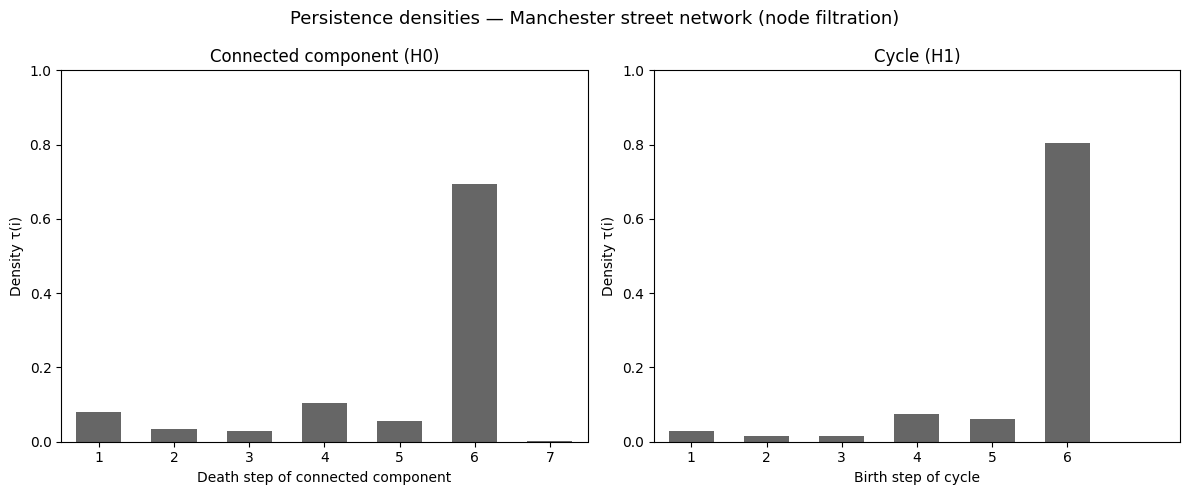

In [73]:
# -----------------------------
# PERSISTENCE DENSITY
# -----------------------------
def persistence_density(intervals, max_persistence=None):
    finite = intervals[np.isfinite(intervals).all(axis=1)] if len(intervals) > 0 else np.empty((0, 2))
    if len(finite) == 0:
        return np.array([]), np.array([])

    lengths = (finite[:, 1] - finite[:, 0]).astype(int)
    total = len(finite)

    if max_persistence is None:
        max_persistence = int(lengths.max())
        print(max_persistence)

    i_values = np.arange(1, max_persistence + 1)
    density = np.array([np.sum(lengths == i) / total for i in i_values])
    return i_values, density


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (intervals, label, dim) in zip(axes, [
    (h0, "Connected component (H0)", "H0"),
    (h1, "Cycle (H1)",               "H1"),
]):

    i_vals, dens = persistence_density(intervals, max_persistence=None)

    if dim == "H1":
        dens = dens[::-1]   # reverse only for H1

    print(i_vals, dens)

    if len(i_vals) == 0:
        ax.set_title(f"No finite {dim} intervals")
        continue

    ax.bar(i_vals, dens, color="#666666", width=0.6)
    ax.set_xlim(0.5, len(highway_order) + 0.5)
    ax.set_ylim(0, 1.0)
    ax.set_xticks(i_vals)

    if dim == "H1":
        ax.set_xlabel("Birth step of cycle")
    else:
        ax.set_xlabel("Death step of connected component")

    ax.set_ylabel("Density τ(i)")
    ax.set_title(label)

plt.suptitle("Persistence densities — Manchester street network (node filtration)", fontsize=13)
plt.tight_layout()
plt.savefig('man_total_density.pdf')
plt.show()

In [ ]:
import numpy as np
import osmnx as ox
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.patches as mpatches
import networkx as nx

DISTINCT_COMPONENT_COLORS = [
    "#0000ff", "#ff0000", "#00ff00", "#000033", "#ff00b6",
    "#005300", "#ffd300", "#009fff", "#9a4d42", "#00ffbe",
    "#783fc1", "#1f9698", "#f10dff", "#b1cc71", "#f1085c",
    "#fe8f42", "#dd00ff", "#201a01", "#720055", "#766c95",
]

def get_component_colors(n_components):
    if n_components <= len(DISTINCT_COMPONENT_COLORS):
        return DISTINCT_COMPONENT_COLORS[:n_components]
    fallback = cm.get_cmap("nipy_spectral", n_components)
    return [fallback(i) for i in range(n_components)]


def plot_connected_components_pdf(H, highway_types, filtration_time, filename, title):
    max_t = max(filtration_time[hw] for hw in highway_types)
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= max_t]

    G_t = nx.Graph()
    G_t.add_nodes_from(H.nodes())  # all nodes always present
    G_t.add_edges_from(edges_t)

    components = sorted(nx.connected_components(G_t), key=len, reverse=True)
    n_components = len(components)

    print(f"{filename}: {n_components} components, {G_t.number_of_nodes()} nodes, {G_t.number_of_edges()} edges")

    nodes_gdf = ox.graph_to_gdfs(G, edges=False)
    pos = {
        node: (nodes_gdf.loc[node, "x"], nodes_gdf.loc[node, "y"])
        for node in G_t.nodes() if node in nodes_gdf.index
    }

    fig, ax = plt.subplots(figsize=(15, 12))

    colors = get_component_colors(n_components)
    node_to_comp = {}
    legend_handles = []

    for idx, comp in enumerate(components):
        legend_handles.append(
            mpatches.Patch(
                facecolor=colors[idx],
                edgecolor="black",
                label=f"Component {idx + 1} ({len(comp)} nodes)",
            )
        )
        for node in comp:
            node_to_comp[node] = idx

    valid_edges = [(u, v) for u, v in G_t.edges() if u in pos and v in pos]
    large_edges = [(u, v) for u, v in valid_edges if len(components[node_to_comp[u]]) > 10]
    small_edges = [(u, v) for u, v in valid_edges if len(components[node_to_comp[u]]) <= 10]

    nx.draw_networkx_edges(
        G_t, pos, edgelist=large_edges, ax=ax,
        edge_color=[colors[node_to_comp[u]] for u, v in large_edges],
        width=1.0, alpha=0.7
    )
    nx.draw_networkx_edges(
        G_t, pos, edgelist=small_edges, ax=ax,
        edge_color=[colors[node_to_comp[u]] for u, v in small_edges],
        width=1.0, alpha=1.0
    )

    small_nodes = [
        n for comp in components if len(comp) <= 10
        for n in comp if n in pos
    ]
    nx.draw_networkx_nodes(
        G_t, pos, nodelist=small_nodes, node_size=0.1,
        node_color=[colors[node_to_comp[n]] for n in small_nodes], ax=ax
    )

    ax.text(
        0.02, 0.98, f"Connected components: {n_components}",
        transform=ax.transAxes, ha="left", va="top", fontsize=11,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="black", alpha=0.9),
    )
    ax.legend(
        handles=legend_handles, title="Colors used", loc="upper left",
        bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0, frameon=True,
        fontsize=8, title_fontsize=10,
        ncol=1 if n_components <= 10 else 2,
    )
    fig.subplots_adjust(right=0.75)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, fontsize=14)

    fig.savefig(filename, format="pdf", bbox_inches="tight")
    plt.close(fig)
    print(f"Saved: {filename}")


import os
os.makedirs("steps_mde_nodes", exist_ok=True)

cumulative = []
for i, hw in enumerate(highway_order):
    cumulative.append(hw)
    label = "_".join(cumulative)
    title = "All nodes + " + " + ".join(cumulative) + " — connected components"
    plot_connected_components_pdf(
        H, cumulative, filtration_time,
        f"steps_mde_nodes/step_{i:02d}_{label}.pdf",
        title
    )

steps_mde_nodes/step_00_trunk.pdf: 46590 components, 47009 nodes, 423 edges


/var/folders/1z/lkjj_d294bg99hybc2v704bm0000gn/T/ipykernel_63792/879981023.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  fallback = cm.get_cmap("nipy_spectral", n_components)


KeyboardInterrupt: 

In [10]:
highway_order = [
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "unclassified",
    "residential",
]

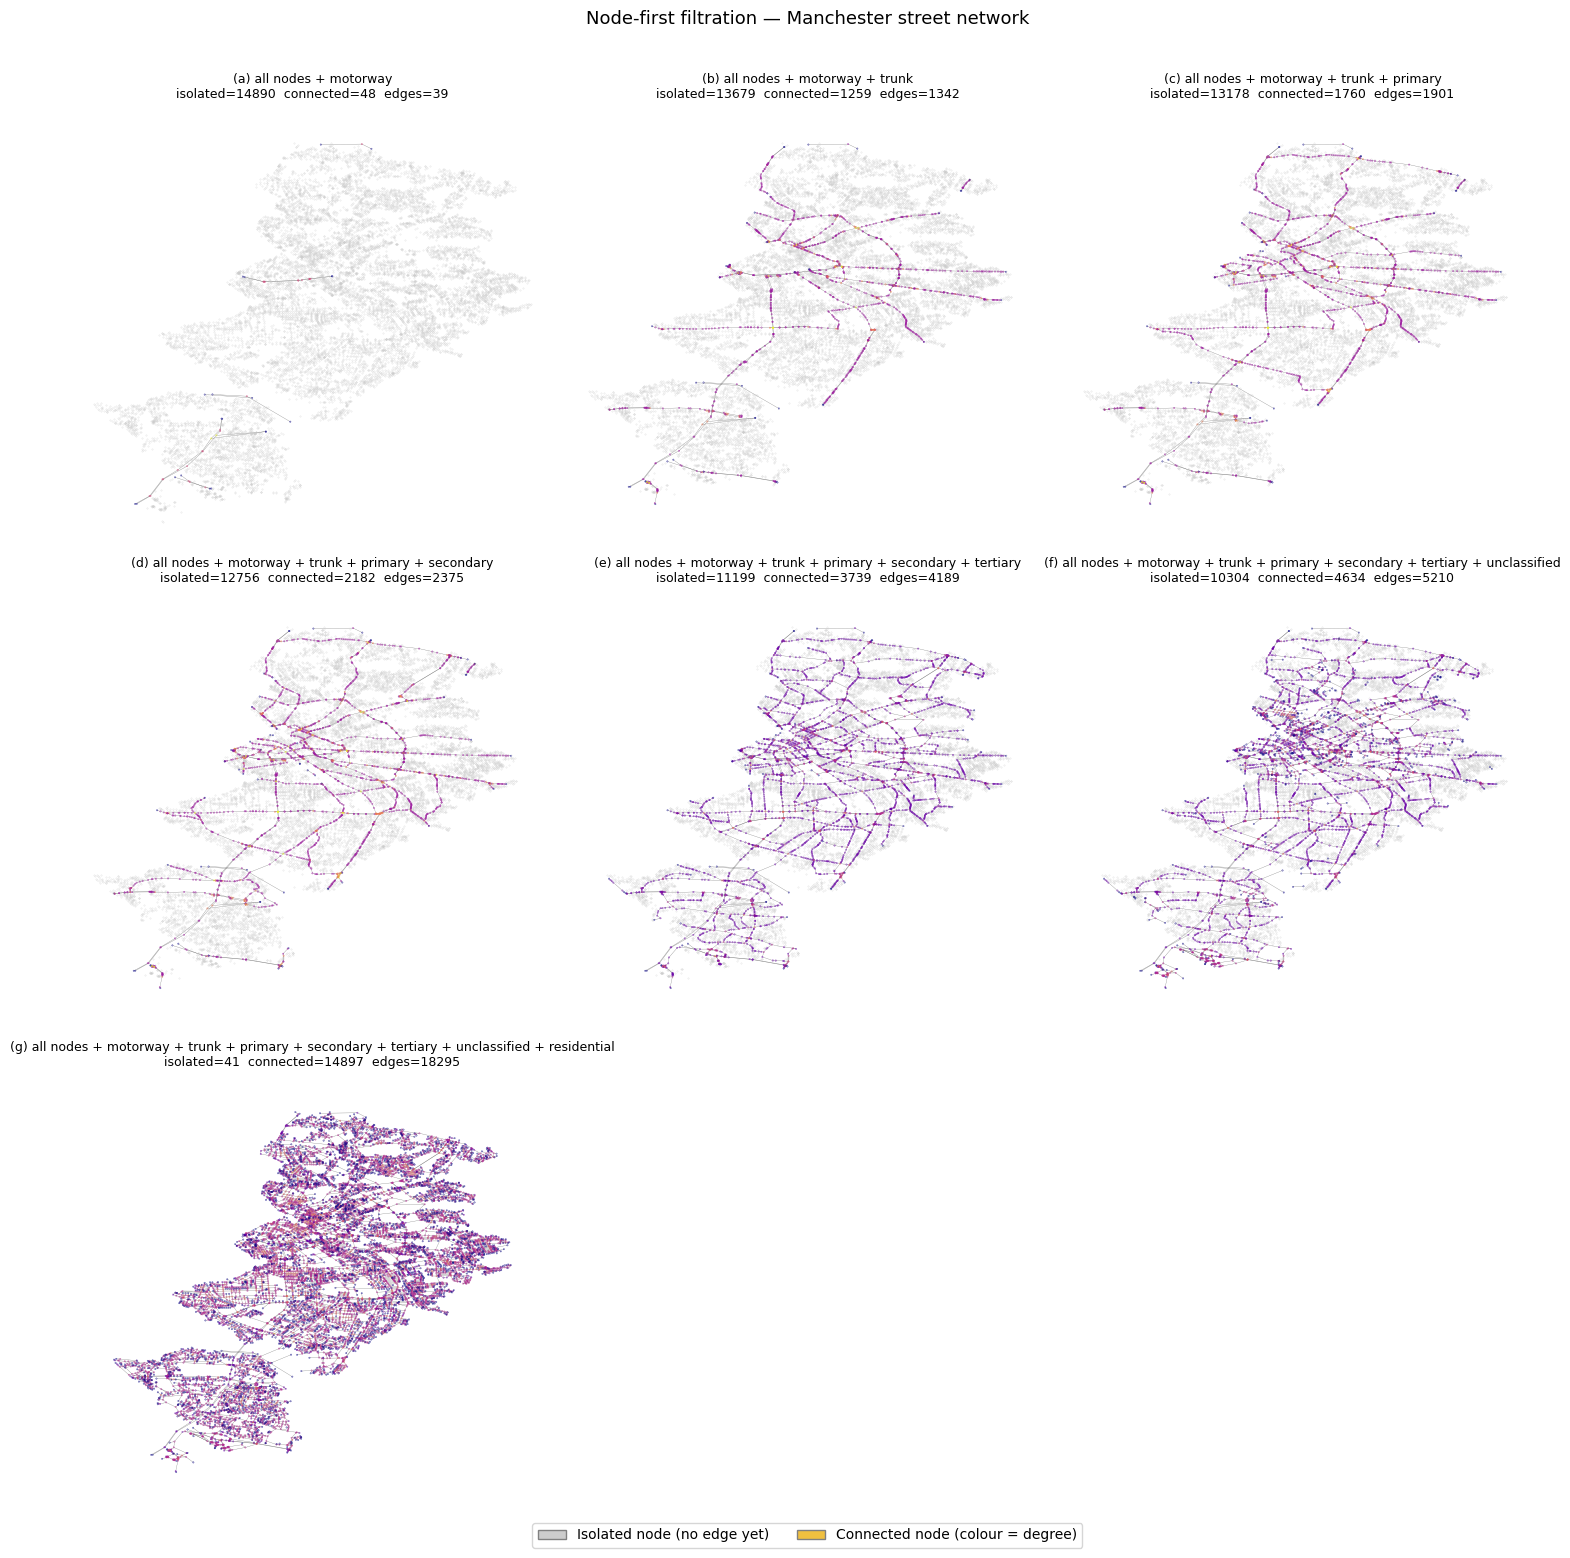

In [74]:
# -----------------------------
# FILTRATION PLOT WITH NODES
# All nodes present at every step (filtration=0).
# Edges added cumulatively by road type.
# Node size scales with degree at each step.
# -----------------------------
import numpy as np
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

nodes_gdf = ox.graph_to_gdfs(G, edges=False)
pos = {node: (nodes_gdf.loc[node, "x"], nodes_gdf.loc[node, "y"])
       for node in H.nodes() if node in nodes_gdf.index}

n = len(highway_order)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()

cumulative_types = []

for i, hw in enumerate(highway_order):
    cumulative_types.append(hw)
    max_t = filtration_time[hw]

    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= max_t]

    G_t = nx.Graph()
    G_t.add_nodes_from(H.nodes())
    G_t.add_edges_from(edges_t)

    ax = axes[i]

    # Isolated nodes (degree 0) vs connected nodes
    degrees = dict(G_t.degree())
    isolated = [n for n, d in degrees.items() if d == 0 and n in pos]
    connected = [n for n, d in degrees.items() if d > 0 and n in pos]

    valid_edges = [(u, v) for u, v in G_t.edges() if u in pos and v in pos]

    # Draw edges
    nx.draw_networkx_edges(G_t, pos, edgelist=valid_edges, ax=ax,
                           edge_color="#333333", width=0.2, alpha=0.7)

    # Draw isolated nodes (small, grey)
    if isolated:
        nx.draw_networkx_nodes(G_t, pos, nodelist=isolated, ax=ax,
                               node_size=0.075, node_color="#cccccc", alpha=0.6)

    # Draw connected nodes (larger, coloured by degree)
    if connected:
        deg_vals = np.array([degrees[n] for n in connected], dtype=float)
        # Normalise to [5, 40] for node size
        if deg_vals.max() > deg_vals.min():
            sizes = 5 + 35 * (deg_vals - deg_vals.min()) / (deg_vals.max() - deg_vals.min())
        else:
            sizes = np.full(len(connected), 10.0)
        nx.draw_networkx_nodes(G_t, pos, nodelist=connected, ax=ax,
                               node_size=0.075, node_color=deg_vals,
                               cmap="plasma", alpha=0.9)

    n_iso = len(isolated)
    n_con = len(connected)
    n_edges = len(valid_edges)
    ax.set_title(
        f"({chr(97+i)}) all nodes + {' + '.join(cumulative_types)}\nisolated={n_iso}  connected={n_con}  edges={n_edges}",
        fontsize=9
    )
    ax.set_axis_off()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

# Shared legend
legend_handles = [
    mpatches.Patch(facecolor="#cccccc", edgecolor="grey", label="Isolated node (no edge yet)"),
    mpatches.Patch(facecolor="#f0c040", edgecolor="grey", label="Connected node (colour = degree)"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=2, fontsize=10,
           bbox_to_anchor=(0.5, -0.02))

plt.suptitle("Node-first filtration — Manchester street network", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()